# CompFlow demo: from two frames to a dense motion map

This notebook illustrates how the public **CompFlow** repository (https://github.com/migueldiaz1/CompFlow-OFV) works, end to end, on a `SynthCells` sample pair:

1. load a frame pair from the repo's bundled sample data,
2. look at it -- full cell, then three 30x30 zoomed regions,
3. run `CompFlow-Patch` (the method proposed in the paper) on it to get a dense motion map,
4. plot that motion map -- full cell as a dense per-pixel direction map, zoom as colored quiver arrows.

Plotting/zoom-picking code lives in `utils.py`, kept out of the way so this notebook only shows the actual repo API (`estimate_flow`, `load_pair`, `n_pairs`).

Run `setup.sh` (Linux/macOS) or `setup.bat` (Windows) once to create the virtual environment this notebook runs in, then open it and pick the "Python 3" kernel.

In [1]:
import os
import sys

import numpy as np
import matplotlib.pyplot as plt
import torch

REPO = os.getcwd()          # this repo's own root (CompFlow code + notebook live side by side here)
sys.path.insert(0, REPO)
sys.path.insert(0, os.path.join(REPO, "Datasets"))
sys.path.insert(0, os.path.join(REPO, "Metrics"))

from inference import estimate_flow          # repo's public API
from load_sample import load_pair, n_pairs   # repo's sample-data loader
from utils import pick_zoom_regions, plot_pair_and_zooms, plot_motion_map_with_gt

print("torch", torch.__version__, "| cuda available:", torch.cuda.is_available())
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

/home/migueldi/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


torch 2.5.1+cu121 | cuda available: True


## 1. Load a SynthCells sample pair

`Datasets/SynthCells_sample.zip` ships 30 pairs with dense ground truth (not needed here, just the frames).

In [2]:
ZIP_PATH = os.path.join(REPO, "Datasets", "SynthCells_sample.zip")

# Fixed seed, chosen deliberately: among all 30 pairs in the sample, this
# one (#14) gets the lowest CompFlow-Patch AEPE against ground truth
# (0.0407 px, vs. 0.0430-0.0547 px for the rest) -- the clearest example
# of the method working well.
SEED = 1
rng_pair = np.random.default_rng(SEED)
PAIR_IDX = int(rng_pair.integers(0, n_pairs(ZIP_PATH)))

print(f"{n_pairs(ZIP_PATH)} pairs available in {os.path.basename(ZIP_PATH)} -- using pair #{PAIR_IDX} (seed={SEED})")
img1, img2, gt = load_pair(ZIP_PATH, PAIR_IDX)
mask = gt["mask"]
print(f"frame shape: {img1.shape}, dtype: {img1.dtype}")

30 pairs available in SynthCells_sample.zip -- using pair #14 (seed=1)
frame shape: (256, 256), dtype: uint8


## 2. Full cell, then three 30x30 zoomed regions

Three interior points of the cell mask, spread apart, each giving a 30x30 crop.

In [3]:
ZOOM = 30
ZOOM_COLORS = ["#e6194b", "#3cb44b", "#4363d8"]

zoom_regions = pick_zoom_regions(mask, size=ZOOM, n=3, seed=None)
print("zoom regions (y0, x0):", zoom_regions)

zoom regions (y0, x0): [(np.int64(80), np.int64(129)), (np.int64(126), np.int64(171)), (np.int64(141), np.int64(142))]


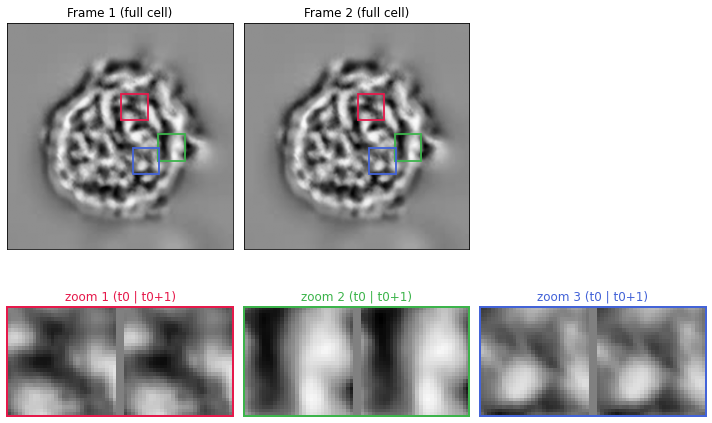

In [4]:
plot_pair_and_zooms(img1, img2, zoom_regions, ZOOM_COLORS, ZOOM)

## 3. Dense motion map with CompFlow-Patch (from the GitHub repo)

`dataset="SynthCells"` pulls the exact SynthCells-calibrated parameters the paper uses for this method (`CompFlow/configs/dataset_params.json`) -- no parameters to set by hand.

In [5]:
torch.manual_seed(0)
u_gh, v_gh = estimate_flow(img1, img2, method="CompFlow-Patch", dataset="SynthCells", device=DEVICE)

print(f"u: shape={u_gh.shape}  mean={u_gh.mean():.4f}")
print(f"v: shape={v_gh.shape}  mean={v_gh.mean():.4f}")
print(f"|w| mean (inside mask) = {np.hypot(u_gh, v_gh)[mask > 0].mean():.4f} px/frame")

u: shape=(256, 256)  mean=0.0003
v: shape=(256, 256)  mean=-0.0005
|w| mean (inside mask) = 0.0663 px/frame


## 4. Plotting the dense motion map

**Full cell = a fully dense per-pixel direction map** (every pixel gets a color, no arrows -- arrows that dense would just be a solid block); **zoom = actual colored quiver arrows** (hue = direction, same HSV colormap as the dense map, thickness tiered by magnitude, staggered grid so the spacing looks even). SynthCells ships dense per-pixel ground truth, so the direction and magnitude columns are each shown **twice, side by side: `CompFlow-Patch` (estimated) vs. ground truth** -- 7 columns in total.

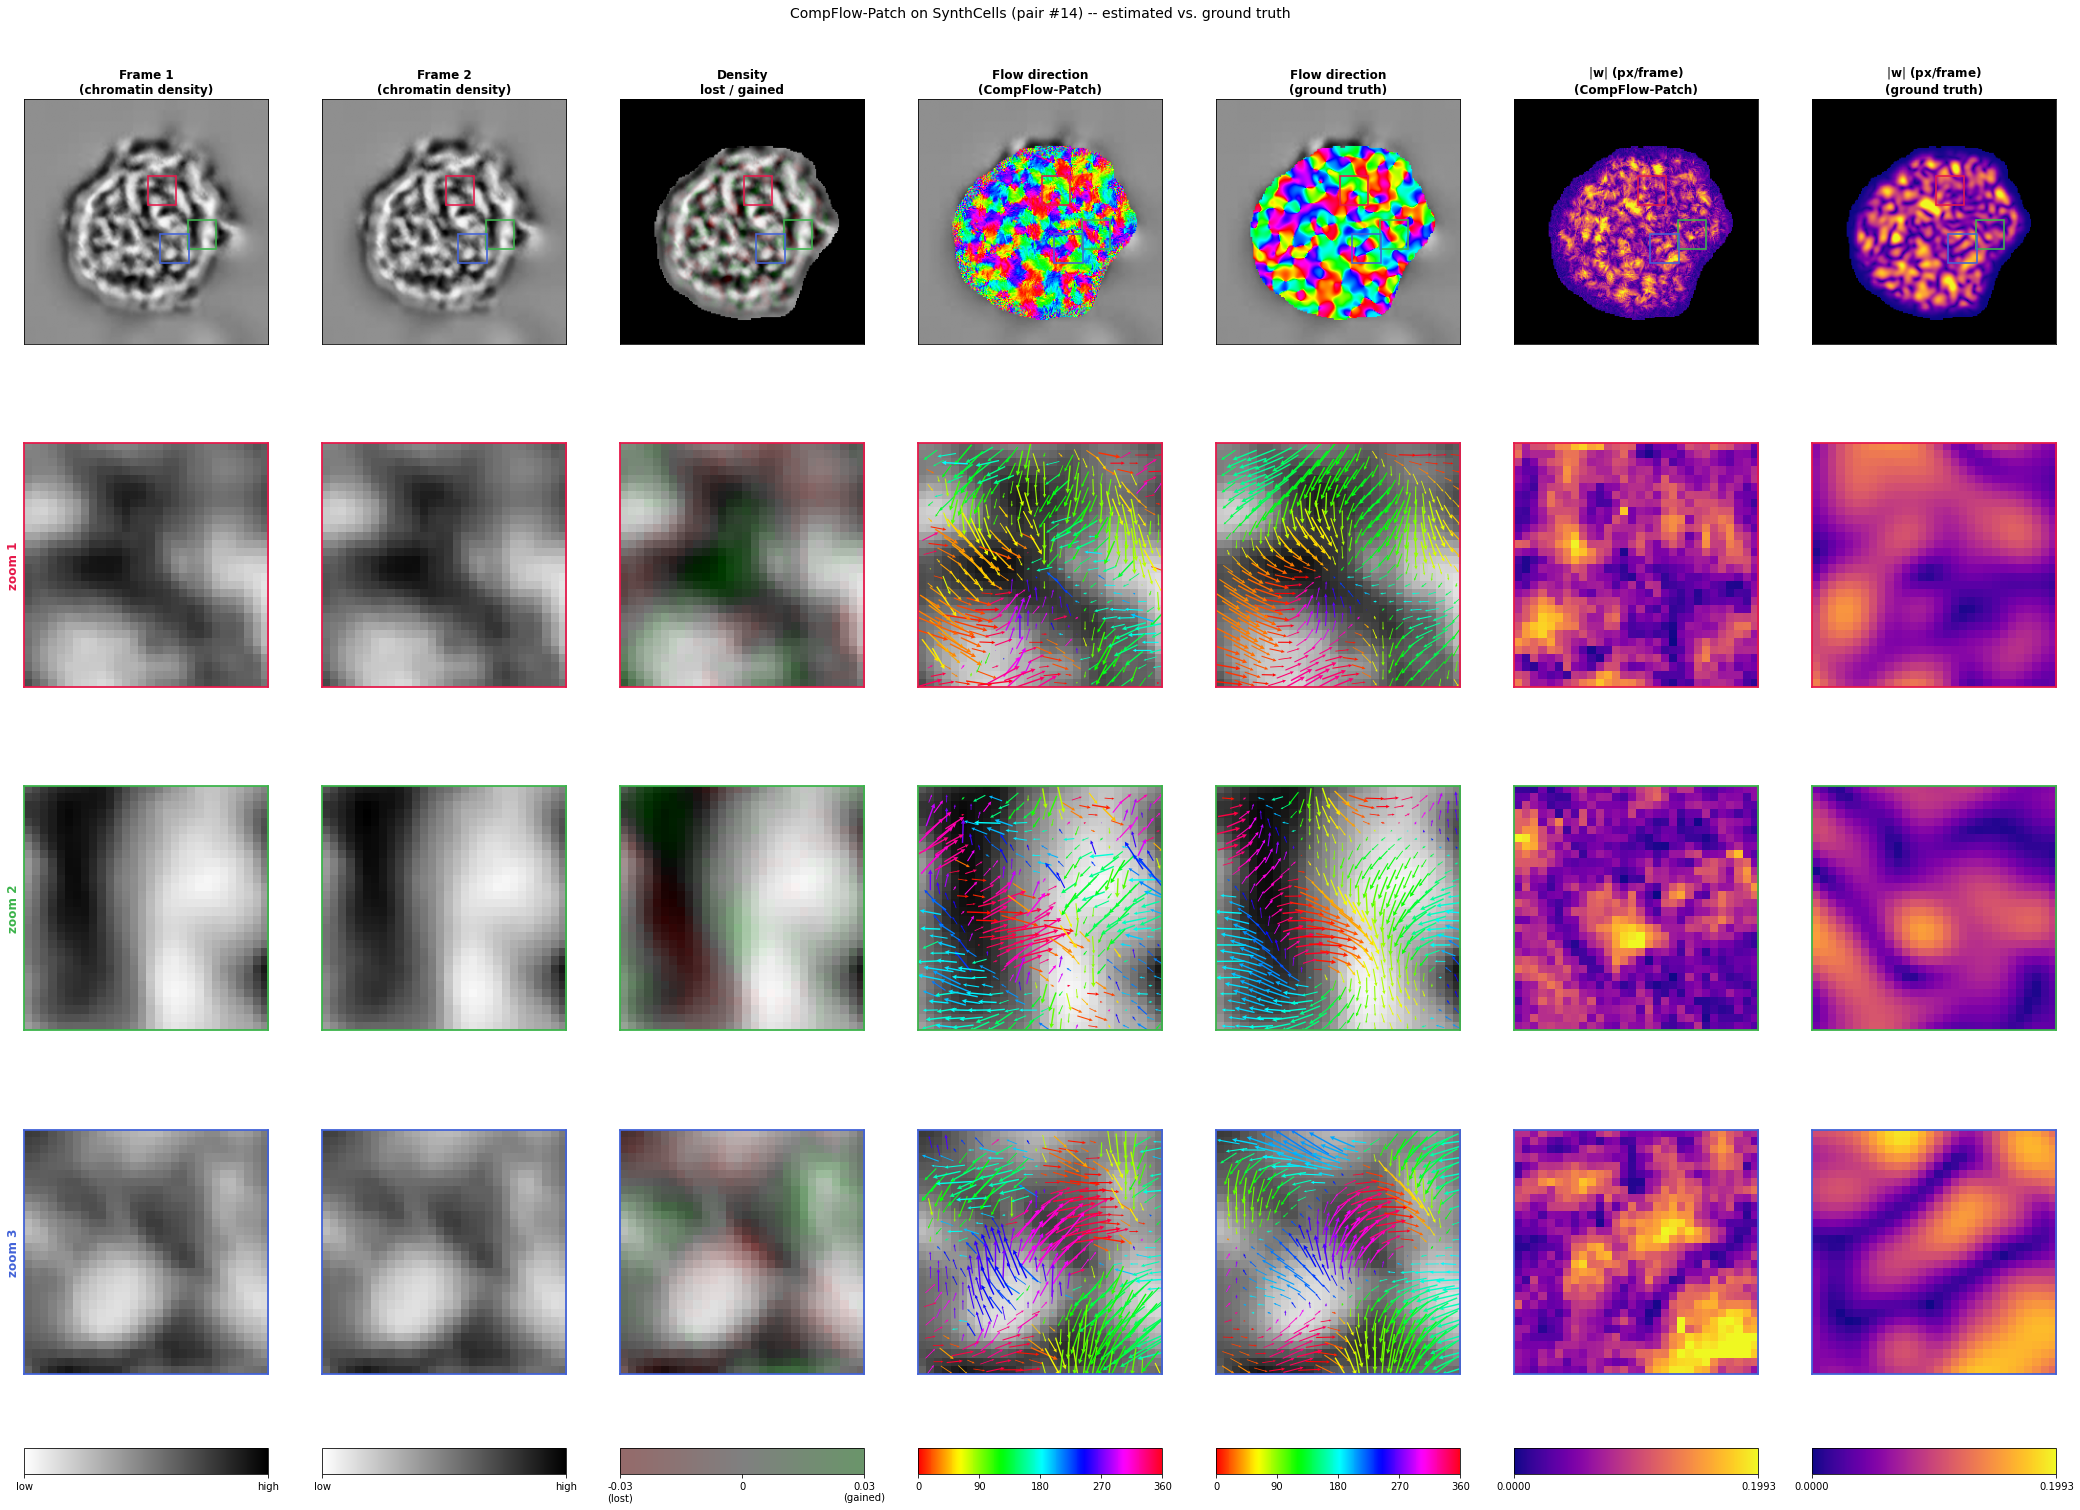

In [6]:
plot_motion_map_with_gt(
    img1, img2, mask, u_gh, v_gh, gt["u_gt"], gt["v_gt"],
    zoom_regions, ZOOM_COLORS, ZOOM,
    suptitle=f"CompFlow-Patch on SynthCells (pair #{PAIR_IDX}) -- estimated vs. ground truth",
)